Khai phá dữ liệu MNIST

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

2. Load Data

In [3]:
sys.path.append(os.path.abspath('..')) 
from src.data import load_prepared_mnist
X_train, y_train_oh, X_test, y_test_oh = load_prepared_mnist()
y_train = y_train_oh.argmax(axis=1)
y_test = y_test_oh.argmax(axis=1)

3. Kiểm tra số lượng

In [4]:

print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test :", X_test.shape, X_test.dtype)
print("y_test :", y_test.shape, y_test.dtype)

print("Pixel min:", X_train.min())
print("Pixel max:", X_train.max())

print("Nhãn train:", np.unique(y_train))
print("Nhãn test :", np.unique(y_test))

print("NaN trong train:", np.isnan(X_train).sum())
print("NaN trong test :", np.isnan(X_test).sum())

X_train: (60000, 784) float32
y_train: (60000,) int64
X_test : (10000, 784) float32
y_test : (10000,) int64
Pixel min: 0.0
Pixel max: 1.0
Nhãn train: [0 1 2 3 4 5 6 7 8 9]
Nhãn test : [0 1 2 3 4 5 6 7 8 9]
NaN trong train: 0
NaN trong test : 0


4. Vẽ biểu đồ số lượng mỗi lớp

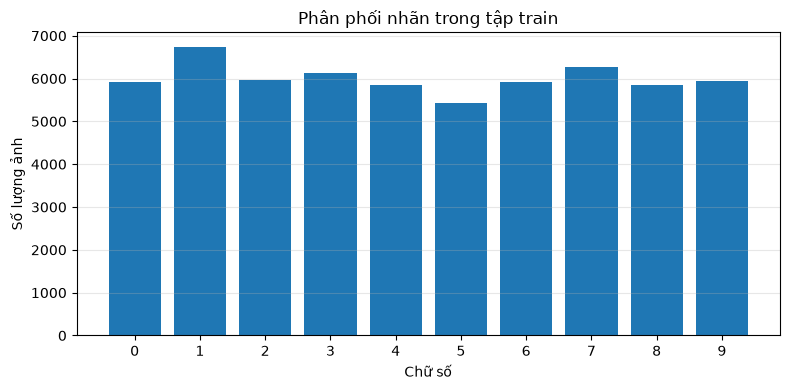

0: 5923 ảnh (9.87%)
1: 6742 ảnh (11.24%)
2: 5958 ảnh (9.93%)
3: 6131 ảnh (10.22%)
4: 5842 ảnh (9.74%)
5: 5421 ảnh (9.04%)
6: 5918 ảnh (9.86%)
7: 6265 ảnh (10.44%)
8: 5851 ảnh (9.75%)
9: 5949 ảnh (9.92%)


In [5]:

classes, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(8, 4))
plt.bar(classes, counts)
plt.xticks(range(10))
plt.xlabel("Chữ số")
plt.ylabel("Số lượng ảnh")
plt.title("Phân phối nhãn trong tập train")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for digit, count in zip(classes, counts):
    print(f"{digit}: {count} ảnh ({count / len(y_train) * 100:.2f}%)")

Nhận xét: Các lớp trong mẫu phân bố khá đồng đều (9% - 11,2%), lớp 1 nhiều nhất, lớp 5 ít nhất

5. In ra 1 ảnh minh họa mỗi classes

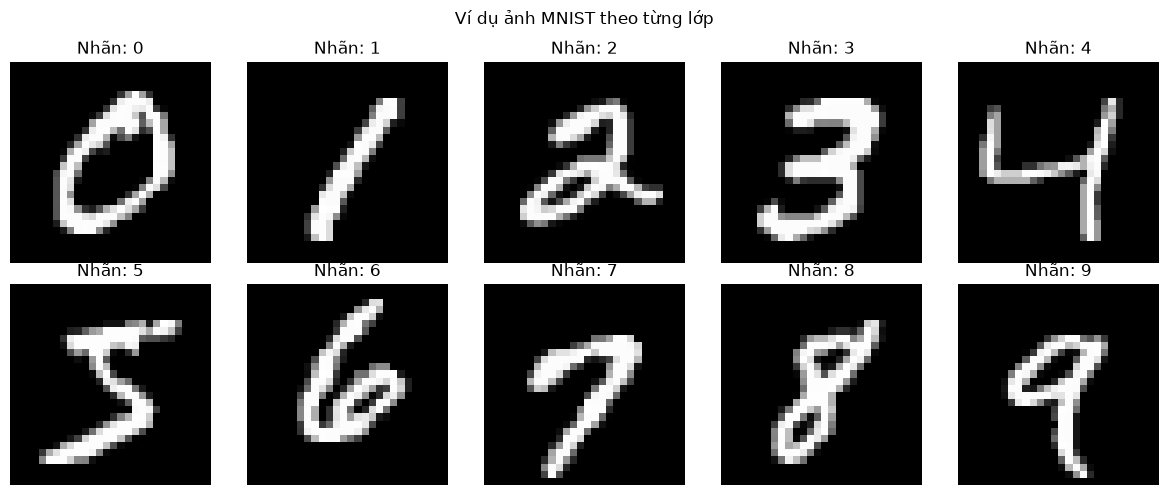

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for digit, ax in enumerate(axes.flat):
    idx = np.where(y_train == digit)[0][0]

    ax.imshow(X_train[idx].reshape(28,28), cmap="gray")
    ax.set_title(f"Nhãn: {y_train[idx]}")
    ax.axis("off")

plt.suptitle("Ví dụ ảnh MNIST theo từng lớp")
plt.tight_layout()
plt.show()

6. Đo độ phân tán các mẫu bằng PCA và TSNE

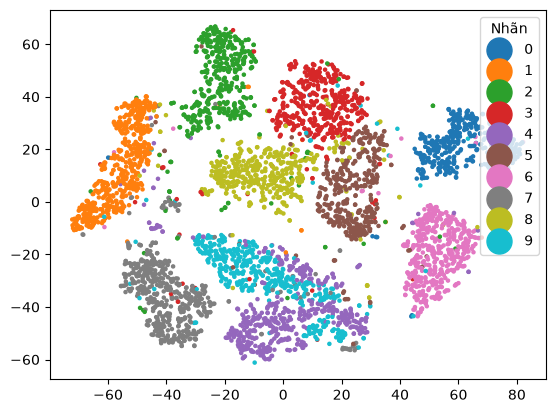

In [15]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Xf = X_train[:5000].reshape(5000, -1) 
Xp = PCA(n_components=50).fit_transform(Xf)
Xt = TSNE(n_components=2, random_state=42).fit_transform(Xp)
sc = plt.scatter(Xt[:, 0], Xt[:, 1], c=y_train[:5000], cmap="tab10", s=5)

handles, labels = sc.legend_elements()
plt.legend(handles, labels, loc="upper right", title="Nhãn", markerscale=3)
plt.show()

7. Đo độ thưa mỗi ảnh

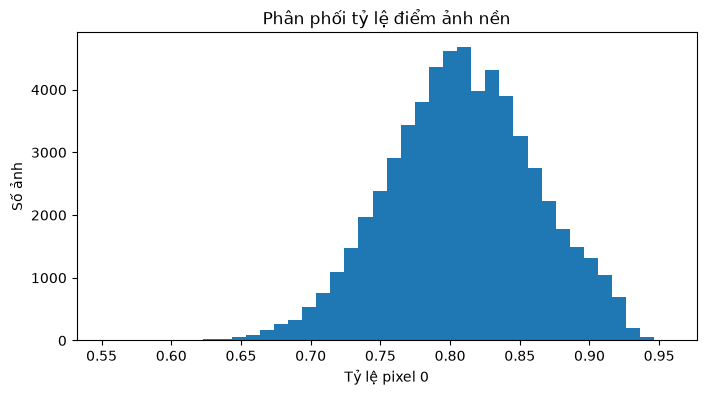

In [10]:
zero_ratio = (X_train == 0).mean(axis=1)

plt.figure(figsize=(8, 4))
plt.hist(zero_ratio, bins=40)
plt.title("Phân phối tỷ lệ điểm ảnh nền")
plt.xlabel("Tỷ lệ pixel 0")
plt.ylabel("Số ảnh")
plt.show()

Nhận xét : 

Dữ liệu có 60000 mẫu train, 10000 mẫu test, kích thước 28x28 và được trải phẳng thành 784 chiều
Không phát hiện NaN trong tập train và test
Các lớp tương đối cân bằng, vì vậy accuracy phù hợp làm metric chính; tuy nhiên vẫn cần báo cáo macro-F1 và confusion matrix ở phần mô hình.
Nền ảnh chiếm phần lớn pixel bằng 0; các lớp có nét tương đồng như 3/5/8, 4/9  có thể là nguồn nhầm lẫn cần kiểm tra sau huấn luyện.